<h5>Augmented LLM with Tools</h5>

Augmented LLM with Search Tool: Here we will build a simple augmented LLM using the capabilities of Tavily Search as a tool to allow the LLM to fetch relevant information from the web when necessary. Tavily Search is an free api to search internet.

Setup Environment Variables

In [1]:
import os
from dotenv import load_dotenv, find_dotenv
load_dotenv()

True

In [40]:
api_key = os.getenv('OPENAI_API_KEY')
tavily_api_key = os.getenv('TAVILY_API_KEY')

In [41]:
from typing import Annotated, TypedDict
from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langchain_openai import ChatOpenAI


State

In [42]:
class State(TypedDict):
    messages: Annotated[list[str], add_messages]

In [43]:
llm = ChatOpenAI(model_name="gpt-4o-mini", temperature=0)

In [59]:
from langchain_community.utilities.tavily_search import TavilySearchAPIWrapper
from langchain_core.tools import tool
tavily_search = TavilySearchAPIWrapper()

Augment the LLM with tools

Here we define our custom search tool and then bind it to the LLM to augment the LLM

In [60]:
@tool
def search_web(query: str, num_result=5) -> str:
    """Search the web for a query. Useful for general information or general news"""
    result = tavily_search.raw_results(
        query=query,
        max_results=num_result,
        search_depth='advanced'
    )
    return result

tools = [search_web]
llm_with_tools = llm.bind_tools(tools=tools)

In [61]:
# If you notice here- it has not called any tool. LLM itself is capable to answer to this user query.
llm_with_tools.invoke('what is AI in 1 line')

AIMessage(content='AI, or artificial intelligence, is the simulation of human intelligence processes by machines, particularly computer systems, enabling them to perform tasks that typically require human intelligence.', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 32, 'prompt_tokens': 71, 'total_tokens': 103, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0}, 'prompt_tokens_details': {'audio_tokens': 0, 'cached_tokens': 0}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_54ec6000d4', 'id': 'chatcmpl-EJYdOz4z4hdVf3cgZgz6GOeVnba15', 'service_tier': 'default', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--01a060c7-6074-7dc2-9c6d-2094d5bc17e8-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 71, 'output_tokens': 32, 'total_tokens': 103, 'input_token_details': {'audio': 0, 'ca

We know LLM can not call the toll it is ToolNode which can call the tool. so will build below workflow:



tool_calling_node will take the user query and invoke the LLM and append the LLM response to the Graph state.

if the latest state message has "tool_call" then route the flow to the "tool" node which has "tavily_search tool" else route flow to END node.

ToolNode always has tool and agent can recognize that here are some tolls which i can call.

In [47]:
from langgraph.prebuilt import ToolNode, tools_condition

In [62]:
# Augmented LLM with Tools Node function
def tool_calling_llm(state: State) -> State:
    current_state = state.get('messages', [])
    return {'messages': [llm_with_tools.invoke(current_state)]}

In [81]:
#build the graph
builder  = StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
# ToolNode creates the tool node which an agent can recogine that this node has tolls which i can call if needed.
builder.add_node("tools", ToolNode(tools=tools))

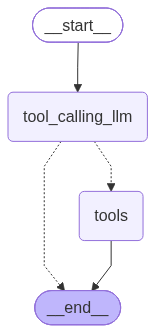

In [82]:
# Conditional Edge
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
                            "tool_calling_llm",
                             # If the latest message (result) from LLM is a tool call -> tools_condition routes to tools
                             # If the latest message (result) from LLM is a not a tool call -> tools_condition routes to END
                            tools_condition,
                            ["tools",END]
                            )

builder.add_edge("tools", END)

graph = builder.compile()
graph

In [79]:
# Notice AIMessage does not have any tool call. this is generated by only LLM, no tool call happened
user_input = "Explain AI in 2 bullets"
for event in graph.stream({"messages": user_input},
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

Explain AI in 2 bullets
================================== Ai Message ==================================

- **Definition**: Artificial Intelligence (AI) refers to the simulation of human intelligence processes by machines, particularly computer systems. These processes include learning (the acquisition of information and rules for using it), reasoning (using rules to reach approximate or definite conclusions), and self-correction.

- **Applications**: AI is utilized in various fields such as healthcare (for diagnostics and personalized medicine), finance (for fraud detection and algorithmic trading), autonomous vehicles, customer service (via chatbots), and many more, enhancing efficiency and decision-making capabilities.


In [83]:
user_input = "What is the latest news on OpenAI product releases"
for event in graph.stream({"messages": user_input},
                          stream_mode='values'):
    event['messages'][-1].pretty_print()

================================ Human Message =================================

What is the latest news on OpenAI product releases
================================== Ai Message ==================================
Tool Calls:
  search_web (call_397Ye5RD2bjoF7hJPwQnLy9P)
 Call ID: call_397Ye5RD2bjoF7hJPwQnLy9P
  Args:
    query: OpenAI product releases news
    num_result: 5
================================= Tool Message =================================
Name: search_web

{"query": "OpenAI product releases news", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://openai.com/research/index/release", "title": "OpenAI Research | Release", "content": "Product\n\nJul 9, 2026\n\nGPT-5.6: Frontier intelligence that scales with your ambition More intelligence from every token, stronger performance per dollar, and more capability on demand for your hardest work.\n\nProduct\n\nJul 8, 2026\n\nIntroducing GPT-Live A new generation of voice models for natural hum